In [8]:
import os
import numpy as np
import uproot
import sys

import matplotlib.pyplot as plt

## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(500)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
# ROOT.enableJSVis()
# ROOT.disableJSVis()

### Compare with MC
I need to do two runs, one with LP and one bare. apply same 'rate scaling' to both datasets.

In [15]:
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")
sys.path.append(os.environ.get("CF4HOME")+"/comp1/helpers/")
import Comparator as comp
import MCdataSet as mcd
print(sys.path)

## Atown's stuff
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

## usually use config.json file to organize all this
class storeConfig:
  pass
conf = storeConfig()
conf.NCA = 0.17
conf.binLow = -0.5
conf.binHigh = 39.5
conf.binWidth = 1.0
conf.Nbins = int((conf.binHigh - conf.binLow) / conf.binWidth)
print(f"Nbins: {conf.Nbins}")

# ------------- User Inputs ------------- #
NCHAN = 3
VERBOSE = False
ASK_MATPLOT = True
DO_2D = False
QVAR_USE = "qFlat"
PECUTVALUE = 0.5

defPath = str(os.environ["CF4HOME"]) + "/procData/"
rootPath = defPath + "/analysis1/"

runID_lp = [202206231023]
runID_bare = [202205201136]
physicsList = runID_bare + runID_lp
allRuns = physicsList

['/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code2analysis', '/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311/lib', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python311.zip', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload', '', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp1/helpers/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4_cf4_updated', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4_cf4_updated/Batch/helpers', '/Users/austindestcroix/Desktop/school_holders/projects/sbc

In [16]:
# ------------- Main Analysis ------------- #
rcList = []
fList = []

for run in allRuns:
    file_path = rootPath + f"npv1_{run}.root"
    f = ROOT.TFile(file_path, "READ")
    fList.append(f)
    tt = f.Get("tt")
    
    rcObj = RunClass(run, tt, fname = file_path)
    rcList.append(rcObj)
    
    rcObj.computeSPE(width=15, verbose=VERBOSE, varname=QVAR_USE, channels=[i for i in range(NCHAN)], nbins = 150)
    rcObj.UprootConstructor()
    # rcList.append(rcObj)

if VERBOSE:
    input("say something to move past bkg SPE plots")

for rc in rcList:
    rc.print()

rcBare = SORTING.pickSingleRC(runID_bare[0], rcList)
rcLp = SORTING.pickSingleRC(runID_lp[0], rcList)



runID: 202205201136
Nevents: 217499.00,   time: 0.65 min
average Rate: 5558.14 Hz
chID:0: spe = 146.44 +/- 0.18     maxChi2 = 145.18
chID:1: spe = 153.75 +/- 0.09     maxChi2 = 199.77
chID:2: spe = 154.97 +/- 0.09     maxChi2 = 430.11

runID: 202206231023
Nevents: 515499.00,   time: 1.19 min
average Rate: 7243.99 Hz
chID:0: spe = 149.89 +/- 0.04     maxChi2 = 962.55
chID:1: spe = 152.41 +/- 0.04     maxChi2 = 656.02
chID:2: spe = 153.36 +/- 0.04     maxChi2 = 1195.08


Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full


2
['chInfo', 'evTime', 'blineV', 'blineE', 'minV', 'timeMin', 'qFixed', 'qFlat', 'tFlatStart', 'tFlatEnd', 'qRCFixed', 'qRCFlat']
<TBranch 'qFixed' at 0x00032e6e3750>


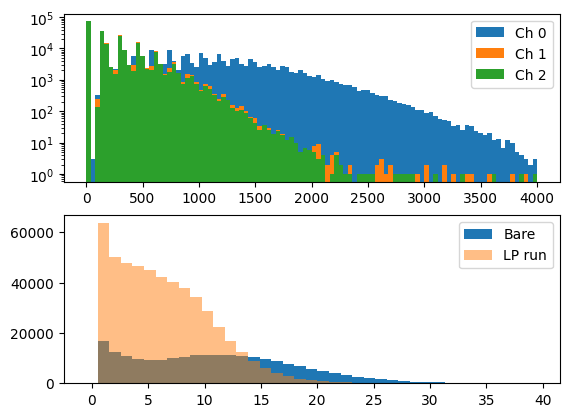

In [17]:
print(len(rcList))

print(rcBare.mttUp.keys())
print(rcBare.mttUp["qFixed"])

qraw = rcBare.mttUp[QVAR_USE].array(library="np")

# for rc in rcList:
#   qa = rc.GetSPEValues(qvar=QVAR_USE)


fig, (axQ, axS) = plt.subplots(2, 1)

qraw = rcBare.mttUp[QVAR_USE].array(library="np")

binEdge = np.linspace(0, 4000, 101)
axQ.hist(qraw[:, 0], bins=binEdge, label="Ch 0")
axQ.hist(qraw[:, 1], bins=binEdge, label="Ch 1")
axQ.hist(qraw[:, 2], bins=binEdge, label="Ch 2")
axQ.legend()
axQ.set_yscale("log")

bE = np.linspace(-0.5, 39.5, 40)

z = axS.hist(rcBare.GetSPEArray(), bins=bE, label = "Bare")
z = axS.hist(rcLp.GetSPEArray(), bins=bE, alpha = 0.5, histtype="stepfilled", label = "LP run")

# axS.set_yscale("log")
axS.legend()
plt.show()
# axS.set_yscale("log")

? 'rate scaling' - R ?
look at absolute rates and if not very different, ignore. just fit spectrum

Light yield - Y

UV fraction - f

okay, looks like rates dont make sense. lets assume its from digitizer busy haha. just do vertical scaling

loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4_cf4_updated/batchOutput_aug25/0/Alpha_vf_0d5_bare.root
6012.561515129543


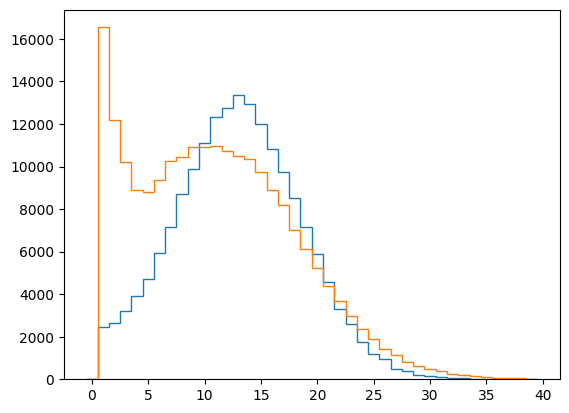

In [49]:
## load in MC data, compare to data
g4BasePath = os.environ.get("CF4G4")
sys.path.append(g4BasePath + "/Batch/helpers")
import G4_runClasses as g4rc
import Comparator as g4comp
g4Path = g4BasePath + "/batchOutput_aug25"


binsDict = {"nbins": conf.Nbins, "low": conf.binLow, "high": conf.binHigh}

## load MC
mcBare_test = g4rc.FullMCRun(macName = g4Path+"/0/Alpha_vf_0d5_bare")
mcBare_test.doCAcorrection_GeometricMC(nCA = conf.NCA)

## setup bins for comparison (same bins)
mcBare_test.setup_forComparison(Nbins = conf.Nbins, lowRange=conf.binLow, maxRange = conf.binHigh)
rcBare.setup_forComparison_np(binArgs = binsDict, qvar=QVAR_USE)

testPair = g4comp.rcMCpair(rcBare, mcBare_test)
testPair.SetBinRanges(5, 40)

scaleMC = testPair.GuessScaling()
print(scaleMC)

## plotting
mcPrefac = scaleMC * rcBare.GetRunTime() / mcBare_test.Nbeam
# mcPrefac = scaleMC / mcBare_test.Nbeam
# plt.hist(rcBare.mBinX, bins = rcBare.mBin_edges, weights = rcBare.mBin_rate, histtype="step", label = "MC");

plt.hist(mcBare_test.mBinX, bins = mcBare_test.mBin_Edges, weights = mcPrefac * mcBare_test.mRaw_Counts, histtype="step", label = "Data");
plt.hist(rcBare.mBinX, bins = rcBare.mBin_edges, weights = rcBare.mBin_rawCounts, histtype="step", label = "MC");